In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
from glob import glob
import xesmf as xe
import xarray as xr
import matplotlib.pyplot as plt

import numpy as np
from datetime import datetime

from matplotlib import patches

import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

from utils import get_shelf_edge, make_map, add_observation_locations

In [2]:
import dask
from dask.distributed import Client, LocalCluster

cluster = LocalCluster(n_workers=5) #number of cores
client = Client(cluster) # go check dask dashboard

In [3]:
# extent =[360-47.5, 360-37.5, -28, -20.62] # max lat fits the gebco data I have for sheld egde contour
extent = [-45, -41, -26, -22]
zoomed_extent= [-45, -39, -27, -22]

# set relative path to the source file
datadir = './../data/aviso_alongtracks/sanagu2022'
savedir = './../figures/aviso/alongtracks/sanagu2022/march_evolution'

timerange = [pd.to_datetime('2022-01-01'), 
             pd.to_datetime('2022-04-01')]

In [4]:
# loading gridded aviso ssh
ds = xr.open_dataset(f"{datadir}/../../sanagu2022/dataset-duacs-nrt-global-merged-allsat-phy-l4_20220101_20220401.nc")

# preparing datset to xESMF
ds = ds.rename({'longitude':'lon', 'latitude':'lat'})

In [5]:
shelf_edge = get_shelf_edge()

In [6]:
bathy = xr.open_dataset('../data/gebco_2019.nc')
# rename variables for a padronization
bathy = bathy.rename({'elevation': 'depth'})
bathy = bathy.where(bathy['depth'] < 0, drop=True)

# regional selection (for both dataset loaded)
lon_lower, lon_upper = zoomed_extent[0], zoomed_extent[1] #-50, -40
lat_lower, lat_upper = zoomed_extent[2], zoomed_extent[3] #-29, -23

# bathymetry
bathy = bathy.sel(lon=slice(lon_lower, lon_upper),
                lat=slice(lat_lower, lat_upper))

In [7]:
###############################################################################
def rotate(x, y, xo=0, yo=0, ang=0):
    import math
    
    theta = np.deg2rad(ang)
    xr=math.cos(theta)*(x-xo)-math.sin(theta)*(y-yo)   + xo
    yr=math.sin(theta)*(x-xo)+math.cos(theta)*(y-yo)  + yo
    
    return [xr,yr]

In [8]:
transects = {
    'cabofrio': {
        "start": (-44.53, -24.53),
        "end": (-41.93, -23.64),
        'ang': 55,
    },
    'offshore_cabofrio': {
        "start": (-45, -26),
        "end": (-41.3, -24),
        'ang': 55,
    },
    'sbb': {
        "start": (-47.38, -27.92),
        "end": (-41.93, -23.64),
        'ang': 30,
    }
}

region = 'cabofrio'
start_lon, start_lat = transects[region]['start']
end_lon, end_lat = transects[region]['end']

path_lats=np.linspace(start_lat,end_lat, 25)
path_lons=np.linspace(start_lon,end_lon, 25)

# use xarray advanced interpolation interp - can't seem to do this pairwise for latlon pairs, for the moment doing it in a loop
section = []
for x in range(25):
    px = ds.sel(lat=path_lats[x], lon=path_lons[x], method = 'nearest') 
    section.append(px)
    
sec = xr.concat(section, dim=path_lats)
ang = np.deg2rad(transects[region]['ang'])
#rotate velocities normal to section
[u_rot, v_rot]=rotate(sec.ugos,sec.vgos,0,0, ang) 

In [9]:
import json

alongshelf_transect = dict(lats=list(path_lats), lons=list(path_lons))
with open('alongshelf_transect.json', 'w') as f:
    json.dump(alongshelf_transect, f)

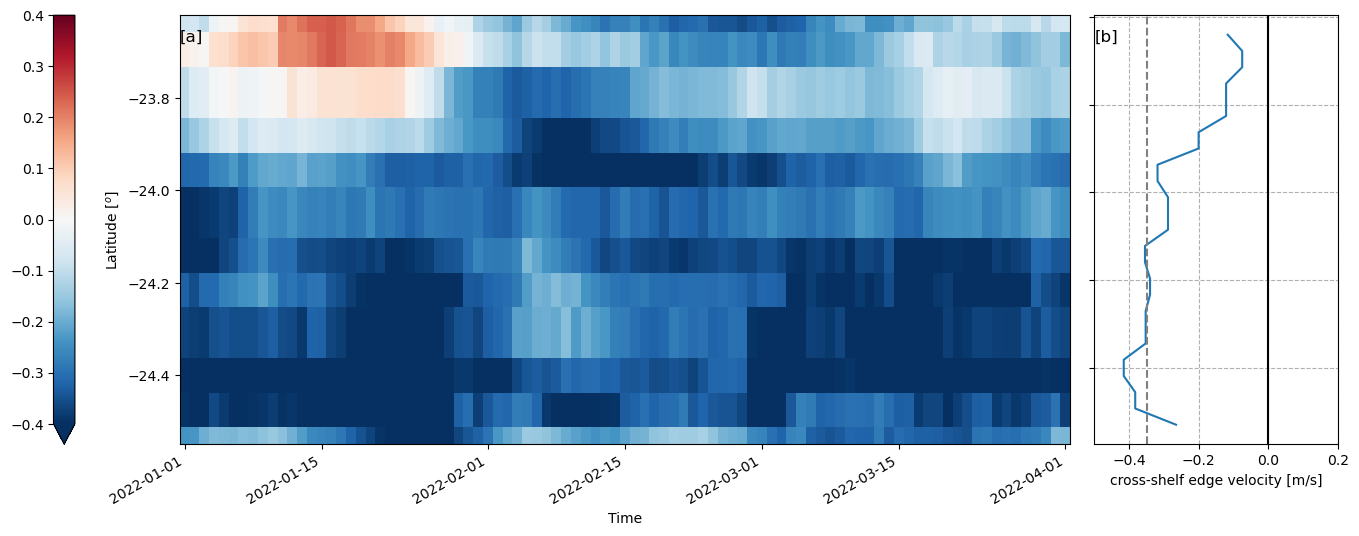

In [10]:
fig_mosaic = """ 
AAAAB
"""
fig,axes = plt.subplot_mosaic(mosaic=fig_mosaic, figsize=(15,5))

#### plotting hovmoller
ax = axes['A']
u_rot.plot(ax=ax, vmin=-.4,vmax=.4,cmap='RdBu_r', cbar_kwargs={'orientation': 'vertical',
                                                               'pad': 0.10, 'location': 'left',
                                                               'fraction': 0.05
                                                               })

plt.xlabel('')
# plt.title('a)', loc='left', fontsize=15, fontweight='bold')
ax.set_ylabel('Latitude [$^o$]')

ax.set_title('[a]', y=0.92, loc='left')



#### plotting time average
ax = axes['B']
u_rot.mean(axis = 1).plot(ax=ax, y='concat_dim')
# plt.axvline(x=u_tm_mean, color = 'gray', linestyle = '--')
ax.axvline(x=-0.35, color = 'gray', linestyle = '--') ### historical 2 standard deviation from the historical avg
ax.axvline(x=0, color = 'black')
# plt.axvline(x=u_tm_median, color = 'k', ls='--')
ax.set_ylabel('')
ax.set_yticklabels('')
ax.set_xlabel('cross-shelf edge velocity [m/s]')
ax.set_title('[b]', y=0.92, loc='left')
ax.grid(True, linestyle='--')
ax.set_xlim([-.5, .2])

plt.tight_layout()
plt.subplots_adjust(top=0.952,
                    bottom=0.094,
                    left=0.083,
                    right=0.96,
                    hspace=0.2,
                    wspace=0.1)

fig.patch.set_alpha(1.0)
# plt.savefig('../figures/manuscript/00_manuscript_cross_geostrophic.png', bbox_inches="tight", dpi=300)

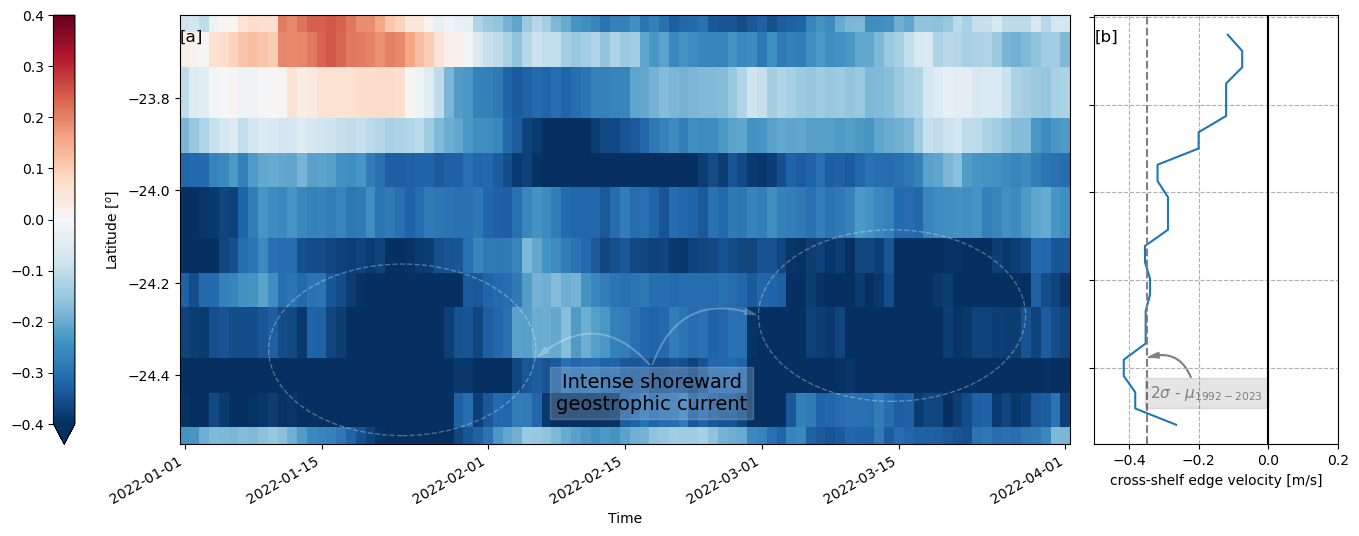

In [136]:
fig_mosaic = """ 
AAAAB
"""
fig,axes = plt.subplot_mosaic(mosaic=fig_mosaic, figsize=(15,5))

#### plotting hovmoller
ax = axes['A']
u_rot.plot(ax=ax, vmin=-.4,vmax=.4,cmap='RdBu_r', cbar_kwargs={'orientation': 'vertical',
                                                               'pad': 0.10, 'location': 'left',
                                                               'fraction': 0.05
                                                               })

plt.xlabel('')
# plt.title('a)', loc='left', fontsize=15, fontweight='bold')
ax.set_ylabel('Latitude [$^o$]')

ax.set_title('[a]', y=0.92, loc='left')

### adding patches to identify intense cross-shelf currents
import matplotlib.patches as mpatches

polygon_kws = dict(width=0.3, height=0.4, 
                   facecolor="None", edgecolor='white', 
                   ls='--', alpha=.3)

ax.add_patch(mpatches.Ellipse(xy=[0.25, 0.22], 
                              transform=ax.transAxes,
                              **polygon_kws)
             )

ax.add_patch(mpatches.Ellipse(xy=[0.8, 0.3],
                              transform=ax.transAxes,
                              **polygon_kws)
             )

t = plt.text(.53, .12, "Intense shoreward\ngeostrophic current", transform=ax.transAxes, 
            ha="center", va="center", fontsize=14)
t.set_bbox(dict(facecolor='white', alpha=0.2, edgecolor='white'))

# # This solution works, but it isn't pretty
style = "Simple, tail_width=0.5, head_width=4, head_length=8"
kw = dict(arrowstyle=style, color="white", alpha=.2)

ax.add_patch(mpatches.FancyArrowPatch((.53, .18), (0.4, 0.2), transform=ax.transAxes,
                             
                             connectionstyle="arc3,rad=.5", **kw)
             )

ax.add_patch(mpatches.FancyArrowPatch((.53, .18), (0.65, 0.3), transform=ax.transAxes,
                             
                             connectionstyle="arc3,rad=-0.5", **kw)
             )

#### plotting time average
ax = axes['B']
u_rot.mean(axis = 1).plot(ax=ax, y='concat_dim')
# plt.axvline(x=u_tm_mean, color = 'gray', linestyle = '--')
ax.axvline(x=-0.35, color = 'gray', linestyle = '--') ### historical 2 standard deviation from the historical avg
ax.axvline(x=0, color = 'black')
# plt.axvline(x=u_tm_median, color = 'k', ls='--')
ax.set_ylabel('')
ax.set_yticklabels('')
ax.set_xlabel('cross-shelf edge velocity [m/s]')
ax.set_title('[b]', y=0.92, loc='left')
ax.grid(True, linestyle='--')
ax.set_xlim([-.5, .2])

t = plt.text(.46, .12, r"2$\sigma$ - $\mu_{1992-2023}$", transform=ax.transAxes, 
            ha="center", va="center", fontsize=11, color="gray")
t.set_bbox(dict(facecolor='k', alpha=0.1, edgecolor='k'))


style = "Simple, tail_width=0.5, head_width=4, head_length=8"
kw = dict(arrowstyle=style, color="gray")

ax.add_patch(mpatches.FancyArrowPatch((.4, .15), (0.21, 0.2), transform=ax.transAxes,
                             
                             connectionstyle="arc3,rad=.5", **kw)
             )
plt.tight_layout()
plt.subplots_adjust(top=0.952,
                    bottom=0.094,
                    left=0.083,
                    right=0.96,
                    hspace=0.2,
                    wspace=0.1)

fig.patch.set_alpha(1.0)
plt.savefig('../figures/manuscript/00_manuscript_cross_geostrophic.png', bbox_inches="tight", dpi=300)

# new version

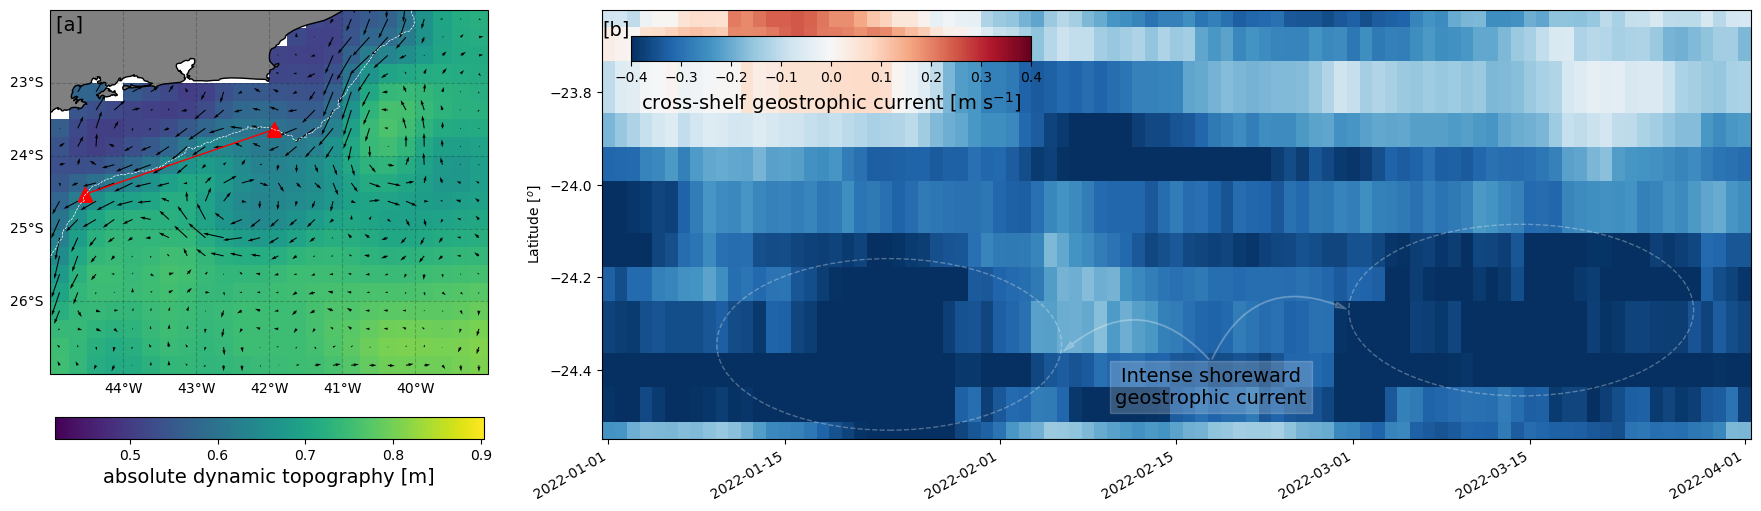

In [78]:
fig_mosaic = """ 
AABBBB
"""
fig,axes = plt.subplot_mosaic(mosaic=fig_mosaic, figsize=(20,5))

#### plotting map
ss = axes['A'].get_subplotspec()
axes['A'].remove()
axes['A'] = fig.add_subplot(ss, projection=ccrs.PlateCarree())
ax = axes['A']

coast = cfeature.NaturalEarthFeature(category='physical', scale='10m',
                            facecolor='none', name='coastline')

feature = ax.add_feature(coast, edgecolor='black',facecolor='gray')
cs = ds.adt.mean(dim='time').plot(ax=ax, transform=ccrs.PlateCarree(),
                                          cbar_kwargs={'orientation': 'horizontal',
                                                       'pad': 0.10, 
                                                       'fraction': 0.05})
plt.plot(start_lon, start_lat, color='red', marker='^', markersize=10, transform=ccrs.PlateCarree())
plt.plot(end_lon, end_lat, color='red', marker='^', markersize=10, transform=ccrs.PlateCarree())

ax.set_extent(zoomed_extent)

ax.plot(shelf_edge["lon"], shelf_edge["lat"], ls="--", c="w", lw="0.5", zorder=10)

_ds = ds.sel(time = '2022-03-12')
ax.quiver(_ds['lon'], _ds['lat'], _ds['ugos'], _ds['vgos'], scale=10)

gl = ax.gridlines(draw_labels=True,
            color='black', alpha=0.2, linestyle='--')
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER
gl.ylabels_right = False
gl.xlabels_top = False

ax.set_title('')
ax.set_title(' [a]', loc='left', y=0.92, c='k', fontsize=14)
#make array of lats and lons for slicing
ax.plot(path_lons, path_lats, color='red', lw=1)

# adjustng colorbar textual elements
cs.colorbar.set_label('absolute dynamic topography [m]', fontsize=14)
cs.colorbar.ax.tick_params(labelsize=10) 

#### plotting hovmoller
ax = axes['B']
cs2 = u_rot.plot(ax=ax, vmin=-.4,vmax=.4, cmap='RdBu_r', add_colorbar=False)

ax.set_xlabel('')
ax.set_ylabel('Latitude [$^o$]')

### adding patches to identify intense cross-shelf currents
import matplotlib.patches as mpatches

polygon_kws = dict(width=0.3, height=0.4, 
                   facecolor="None", edgecolor='white', 
                   ls='--', alpha=.3)

ax.add_patch(mpatches.Ellipse(xy=[0.25, 0.22], 
                              transform=ax.transAxes,
                              **polygon_kws)
             )

ax.add_patch(mpatches.Ellipse(xy=[0.8, 0.3],
                              transform=ax.transAxes,
                              **polygon_kws)
             )

t = plt.text(.53, .12, "Intense shoreward\ngeostrophic current", transform=ax.transAxes, 
            ha="center", va="center", fontsize=14)
t.set_bbox(dict(facecolor='white', alpha=0.2, edgecolor='white'))

# # This solution works, but it isn't pretty
style = "Simple, tail_width=0.5, head_width=4, head_length=8"
kw = dict(arrowstyle=style, color="white", alpha=.2)

ax.add_patch(mpatches.FancyArrowPatch((.53, .18), (0.4, 0.2), transform=ax.transAxes,
                             
                             connectionstyle="arc3,rad=.5", **kw)
             )

ax.add_patch(mpatches.FancyArrowPatch((.53, .18), (0.65, 0.3), transform=ax.transAxes,
                             
                             connectionstyle="arc3,rad=-0.5", **kw)
             )

ax.set_title('[b]', y=0.92, loc='left', fontsize=14)

## adding colorbars
cax = fig.add_axes([0.4, 0.85, 0.2, 0.05])
cbar = fig.colorbar(cs2, cax=cax, orientation='horizontal')
cbar.set_label(r'cross-shelf geostrophic current [m s$^{-1}$]', fontsize=14)
cbar.ax.tick_params(labelsize=10) 

plt.tight_layout()
plt.subplots_adjust(top=0.952,
                    bottom=0.094,
                    left=0.083,
                    right=0.96,
                    hspace=0.2,
                    wspace=0.25)

fig.patch.set_alpha(1.0)
plt.savefig('../figures/manuscript/00_manuscript_cross_geostrophic_new.png', bbox_inches="tight", dpi=300)